<a href="https://colab.research.google.com/github/RJC862/Titanic-Data/blob/main/titanic_project_rjc665.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TITANIC DATA + MACHINE LEARNING

This project has two short parts:
  Part 1 — explore, clean, and visualize passenger data
  Part 2 — use linear regression to predict passenger age

Run one cell at a time from top to bottom. Replace each TODO.

In [ ]:
from google.colab import files

uploaded = files.upload('titanic_messy.csv')


Saving titanic_messy.csv to titanic_messy.csv/titanic_messy.csv


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 1. IMPORT THE TOOLS
# ─────────────────────────────────────────────────────────────────────────────
# A library is reusable code. We use:
#   pandas      → tables and data cleaning
#   seaborn     → simple statistical charts
#   matplotlib  → chart labels and display
#   sklearn     → machine-learning tools
import base64

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")


Libraries imported successfully!


## PART 1: EXPLORE AND CLEAN THE DATA

In [ ]:
import base64

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

# ─────────────────────────────────────────────────────────────────────────────
# 2. LOAD THE DATA
# ─────────────────────────────────────────────────────────────────────────────
# A DataFrame is a table in pandas.
# `pd.read_csv()` reads a CSV file and returns a DataFrame.
#
# TODO: Put the filename inside pd.read_csv().
# Hint: the file is named titanic_messy.csv

import os

original_data = pd.read_csv("/content/titanic_messy.csv/titanic_messy.csv")

print("The data loaded!")
print("Rows and columns:", original_data.shape)

Libraries imported successfully!
The data loaded!
Rows and columns: (901, 13)


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3. TAKE A FIRST LOOK
# ─────────────────────────────────────────────────────────────────────────────
# Each row represents one passenger. Each column describes that passenger.
# Run these commands one at a time and read their output.

original_data.head()            # First five rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,RescueBoatNote
0,207,0,3,"Backstrom, Mr. Karl Alfred",male,32,1,0,3101278,15.85,NaN,S,NaN
1,708,1,1,"Calderhead, Mr. Edward Pennington",male,42,0,0,PC 17476,26.2875,E24,S,NaN
2,635,0,3,"Skoog, Miss. Mabel",female,9,3,2,347088,27.9,NaN,S,NaN
3,767,0,1,"Brewe, Dr. Arthur Jackson",male,NaN,0,0,112379,39.6,NaN,C,NaN
4,759,0,3,"Theobald, Mr. Thomas Leonard",male,34,0,0,363294,8.05,NaN,S,NaN


In [ ]:
print("Shape:", original_data.shape)       # (number of rows, number of columns)
print("Columns:", list(original_data.columns))


Shape: (901, 13)
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'RescueBoatNote']


In [ ]:
original_data.info()            # Column names, data types, and missing values


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 901 entries, 0 to 900
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   PassengerId     901 non-null    int64 
 1   Survived        901 non-null    int64 
 2   Pclass          901 non-null    object
 3   Name            901 non-null    object
 4   Sex             901 non-null    object
 5   Age             724 non-null    object
 6   SibSp           901 non-null    object
 7   Parch           901 non-null    object
 8   Ticket          901 non-null    object
 9   Fare            901 non-null    object
 10  Cabin           205 non-null    object
 11  Embarked        899 non-null    object
 12  RescueBoatNote  8 non-null      object
dtypes: int64(2), object(11)
memory usage: 91.6+ KB


In [ ]:
original_data.describe(include="all")      # Numerical and categorical summaries


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,RescueBoatNote
count,901.000000,901.000000,901,901,901,724,901,901,901,901,205,899,8
unique,NaN,NaN,6,891,6,91,9,9,681,248,147,7,2
top,NaN,NaN,3,"Jensen, Mr. Niels Peder",male,24,0,0,1601,8.05,B96 B98,S,ledger smudge
freq,NaN,NaN,492,2,578,28,610,683,7,42,4,639,4
mean,446.895671,0.382908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,257.222178,0.486366,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,225.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,448.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,670.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# value_counts() shows how often each category occurs.
print(original_data["Sex"].value_counts(dropna=False))
print(original_data["Embarked"].value_counts(dropna=False))

survival_column = "Survived"


Sex
male      578
female    305
FEMALE      5
Male        5
woman       4
M           4
Name: count, dtype: int64
Embarked
S              639
C              165
Q               77
southampton      5
QUEENSTOWN       5
X                4
cherbourg        4
NaN              2
Name: count, dtype: int64


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4. FIND THE PROBLEMS
# ─────────────────────────────────────────────────────────────────────────────
# Real data can contain blanks, duplicates, inconsistent words, and impossible
# numbers. First, count what we can see.

missing_values = original_data.isna().sum().sort_values(ascending=False)
duplicate_rows = original_data.duplicated().sum()

print("Missing values by column:\n", missing_values)
print("\nExact duplicate rows:", duplicate_rows)


for column in ["Pclass", "Sex", "Embarked"]:
    print(f"\n{column} values:", original_data[column].unique())


Missing values by column:
 RescueBoatNote    893
Cabin             696
Age               177
Embarked            2
PassengerId         0
Sex                 0
Name                0
Pclass              0
Survived            0
Ticket              0
Parch               0
SibSp               0
Fare                0
dtype: int64

Exact duplicate rows: 10

Pclass values: ['3' '1' '2' 'first' '4' '0']

Sex values: ['male' 'female' 'woman' 'FEMALE' 'Male' 'M']

Embarked values: ['S' 'C' 'Q' 'southampton' 'X' 'cherbourg' 'QUEENSTOWN' nan]


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5. CLEAN THE NUMBERS
# ─────────────────────────────────────────────────────────────────────────────
# Work on a copy so the original messy data stays available for comparison.
clean_data = original_data.copy()

# `to_numeric(..., errors="coerce")` converts numbers stored as text.
# Text such as "unknown" becomes NaN (a missing value).
number_columns = ["Age", "Fare", "Pclass", "SibSp", "Parch"]

# Loop through number_columns and convert each one.
for column in number_columns:
    clean_data[column] = pd.to_numeric(clean_data[column], errors="coerce")

# Make a True/False condition for each rule. True means the value is impossible.
# Rules: Age 0–100, Fare >= 0, Pclass 1–3, SibSp/Parch >= 0.
age_is_impossible = (clean_data["Age"] < 0) | (clean_data["Age"] > 100)
fare_is_impossible = clean_data["Fare"] < 0
class_is_impossible = (clean_data["Pclass"] < 1) | (clean_data["Pclass"] > 3)
siblings_is_impossible = clean_data["SibSp"] < 0
parents_is_impossible = clean_data["Parch"] < 0

# Use each condition to replace impossible values with np.nan (missing data).
clean_data.loc[age_is_impossible, "Age"] = np.nan
clean_data.loc[fare_is_impossible, "Fare"] = np.nan
clean_data.loc[class_is_impossible, "Pclass"] = np.nan
clean_data.loc[siblings_is_impossible, "SibSp"] = np.nan
clean_data.loc[parents_is_impossible, "Parch"] = np.nan

# Save this flag BEFORE filling Age. Part 2 needs to know which ages were guesses.
clean_data["AgeNeedsImputation"] = clean_data["Age"].isna()

# The median is the middle value. It is less affected by extreme values.
# First calculate the two medians and give them clear names.
median_age = clean_data["Age"].median()
median_fare = clean_data["Fare"].median()

# Then use those values to fill the missing entries.
clean_data["Age"] = clean_data["Age"].fillna(median_age)
clean_data["Fare"] = clean_data["Fare"].fillna(median_fare)

# The mode is the most common value. `.mode()[0]` selects it.
# Repeat the same two simple steps for each column.
for column in ["Pclass", "SibSp", "Parch"]:
    most_common_value = clean_data[column].mode()[0]
    clean_data[column] = clean_data[column].fillna(most_common_value)

print(clean_data[number_columns].isna().sum())


Age       0
Fare      0
Pclass    0
SibSp     0
Parch     0
dtype: int64


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 6. CLEAN THE WORDS
# ─────────────────────────────────────────────────────────────────────────────
# These steps remove spaces, make capitalization consistent, and combine labels
# that mean the same thing.

clean_data["Sex"] = clean_data["Sex"].astype("string").str.strip().str.lower()

# A dictionary connects each inconsistent label to the label we want.
sex_label_fixes = {"m": "male", "woman": "female"}
clean_data["Sex"] = clean_data["Sex"].replace(sex_label_fixes)

clean_data["Embarked"] = clean_data["Embarked"].astype("string").str.strip().str.lower()

# Map each full port name to its one-letter label: s, c, or q.
port_label_fixes = {"southampton": "s", "cherbourg": "c", "QUEENSTOWN":"q" }
clean_data["Embarked"] = clean_data["Embarked"].replace(port_label_fixes)
clean_data["Embarked"] = clean_data["Embarked"].str.upper()

# Unknown categories become missing so they can be filled consistently.
clean_data.loc[~clean_data["Sex"].isin(["male", "female"]), "Sex"] = pd.NA
clean_data.loc[~clean_data["Embarked"].isin(["S", "C", "Q"]), "Embarked"] = pd.NA

# Calculate the most common label in each column.
most_common_sex = clean_data["Sex"].mode()[0]
most_common_port = clean_data["Embarked"].mode()[0]

# Fill missing labels using the values calculated above.
clean_data["Sex"] = clean_data["Sex"].fillna(most_common_sex)
clean_data["Embarked"] = clean_data["Embarked"].fillna(most_common_port)

print("Sex:", clean_data["Sex"].unique())
print("Embarked:", clean_data["Embarked"].unique())


Sex: <StringArray>
['male', 'female']
Length: 2, dtype: string
Embarked: <StringArray>
['S', 'C', 'Q']
Length: 3, dtype: string


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 7. REMOVE DUPLICATES AND AN EMPTY COLUMN
# ─────────────────────────────────────────────────────────────────────────────
rows_before = len(clean_data)

# Remove exact duplicates.
clean_data = clean_data.drop_duplicates()

# RescueBoatNote is almost completely empty, so it is not useful here.
# First drop the column. Then reset the row numbers as a separate step.
clean_data = clean_data.drop(columns=["RescueBoatNote"])
clean_data = clean_data.reset_index(drop=True)

print("Rows removed:", rows_before - len(clean_data))
print("Clean shape:", clean_data.shape)


Rows removed: 10
Clean shape: (891, 13)


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 8. CHECK AND SAVE YOUR CLEAN DATA
# ─────────────────────────────────────────────────────────────────────────────
def check_clean_data(data):
    """Print a friendly checklist for Part 1."""
    checks = {
        "No duplicate rows": not data.duplicated().any(),
        "Empty note column removed": "RescueBoatNote" not in data.columns,
        "Age history saved": "AgeNeedsImputation" in data.columns,
        "Required values filled": not data[["Age", "Fare", "Pclass", "SibSp", "Parch", "Sex", "Embarked"]].isna().any().any(),
        "Sex labels are clean": set(data["Sex"].unique()) <= {"male", "female"},
        "Port labels are clean": set(data["Embarked"].unique()) <= {"S", "C", "Q"},
        "Ages are possible": data["Age"].between(0, 100).all(),
    }
    for name, passed in checks.items():
        print("✓" if passed else "✗", name)
    return all(checks.values())

part_1_complete = check_clean_data(clean_data)

# When every check passes, save without the pandas index.
if part_1_complete:
    clean_data.to_csv("TODO", index=False)
    print("Part 1 complete!")


✓ No duplicate rows
✓ Empty note column removed
✓ Age history saved
✓ Required values filled
✓ Sex labels are clean
✓ Port labels are clean
✓ Ages are possible
Part 1 complete!


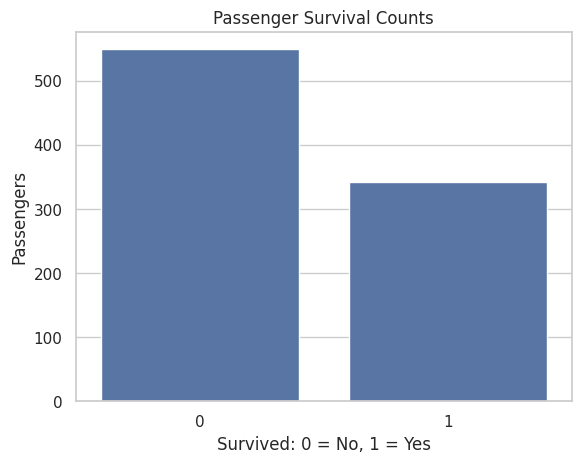

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 9. VISUALIZE THE DATA
# ─────────────────────────────────────────────────────────────────────────────
# A count plot answers: “How many passengers are in each category?”
sns.countplot(data=clean_data, x="Survived")
plt.title("Passenger Survival Counts")
plt.xlabel("Survived: 0 = No, 1 = Yes")
plt.ylabel("Passengers")
plt.show()


Text(0.5, 1.0, 'Survival Rate By Sex')

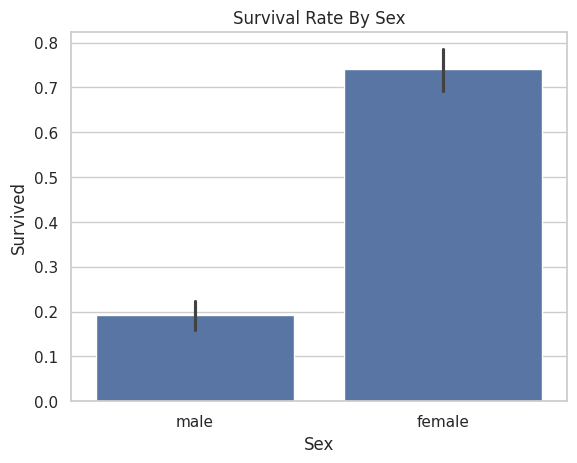

In [ ]:
# TODO: Make a bar plot with Sex on x and Survived on y.
sns.barplot(x="Sex", y="Survived", data=clean_data)
plt.title("Survival Rate By Sex")
# Because Survived is 0/1, the bar height is the survival rate.


Text(0.5, 1.0, 'Survival Rate By Passenger Class')

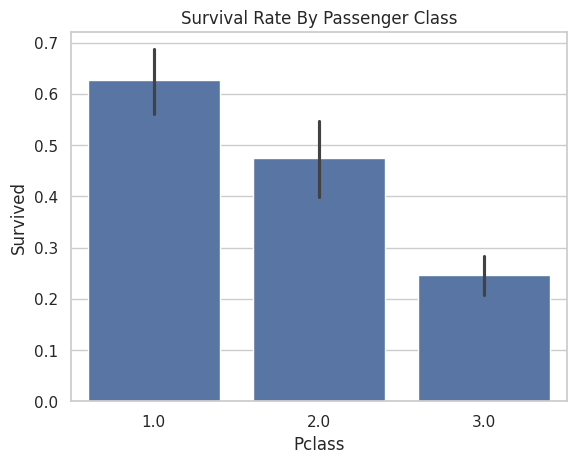

In [ ]:
# Make a bar plot with Pclass on x and Survived on y.
sns.barplot(x="Pclass", y="Survived", data=clean_data)
plt.title("Survival Rate By Passenger Class")


PART 1 REFLECTION — Answer briefly in comments:
1. What was the most surprising data problem?
2. Why was median a reasonable choice for Age or Fare?
3. Which group had the highest survival rate?


## PART 2: PREDICT PASSENGER AGE WITH LINEAR REGRESSION

Classification predicts a category, such as survived/not survived.
Regression predicts a continuous number, such as age, price, or temperature.

Features (X) are the clues given to the model.
The target (y) is the number the model learns to predict.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 10. CHOOSE FEATURES AND TARGET
# ─────────────────────────────────────────────────────────────────────────────
# Never train on filled-in ages: they are guesses, not true answers.
known_age_data = clean_data.loc[~clean_data["AgeNeedsImputation"]].copy()

feature_columns = ["Pclass", "Sex", "Fare", "SibSp", "Parch"]

# Select the input clues and the answer we want the model to learn.
features = clean_data[feature_columns]
ages = clean_data["Age"]

# Models need numbers. get_dummies turns `male`/`female` into numeric columns.
features = pd.get_dummies(
    features,
    columns=["Sex"],
    drop_first=True,
    dtype=int,
)

print("Feature table shape:", features.shape)
print("Target shape:", ages.shape)
print("Features:", list(features.columns))


Feature table shape: (891, 5)
Target shape: (891,)
Features: ['Pclass', 'Fare', 'SibSp', 'Parch', 'Sex_male']


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 11. SPLIT THE DATA
# ─────────────────────────────────────────────────────────────────────────────
# Training data teaches the model. Test data checks it on unseen passengers.
# Complete the split using 20% test data and random_state=42.
training_features, testing_features, training_ages, testing_ages = train_test_split(
    features,
    ages,
    test_size=0.20,
    random_state=42,
)

print("Training rows:", len(training_features))
print("Testing rows:", len(testing_features))


Training rows: 712
Testing rows: 179


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 12. TRAIN AND PREDICT
# ─────────────────────────────────────────────────────────────────────────────
# Linear regression finds a best-fitting relationship. In y = mx + b, m values
# are slopes (coefficients) and b is the intercept.

# Do the model work in three separate steps: create, train, and predict.
model = LinearRegression()
model.fit(training_features, training_ages)
predictions = model.predict(testing_features)

results = pd.DataFrame({
    "Actual Age": testing_ages,
    "Predicted Age": predictions,
})
results["Error"] = results["Actual Age"] - results["Predicted Age"]
results.head(10)


,Actual Age,Predicted Age,Error
709,37.0,25.385577,11.614423
439,36.0,27.775736,8.224264
840,28.0,27.770849,0.229151
720,25.0,33.336782,-8.336782
39,36.0,33.478943,2.521057
290,28.0,27.705151,0.294849
300,29.0,36.935421,-7.935421
333,40.0,27.772209,12.227791
208,28.0,27.773495,0.226505
136,17.0,30.973887,-13.973887


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 13. MEASURE THE MODEL
# ─────────────────────────────────────────────────────────────────────────────
# MAE = average size of an error in years (lower is better).
# MSE = average squared error, so large mistakes matter more (lower is better).
# RMSE = square root of MSE, returning the result to years (lower is better).
# R² = improvement over always guessing average age (higher is better).

# Calculate the four metrics.
mae = mean_absolute_error(testing_ages, predictions)
mse = mean_squared_error(testing_ages, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(testing_ages, predictions)

print(f"MAE:  {mae:.2f} years")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f} years")
print(f"R²:   {r2:.3f}")


MAE:  8.83 years
MSE:  146.52
RMSE: 12.10 years
R²:   0.117


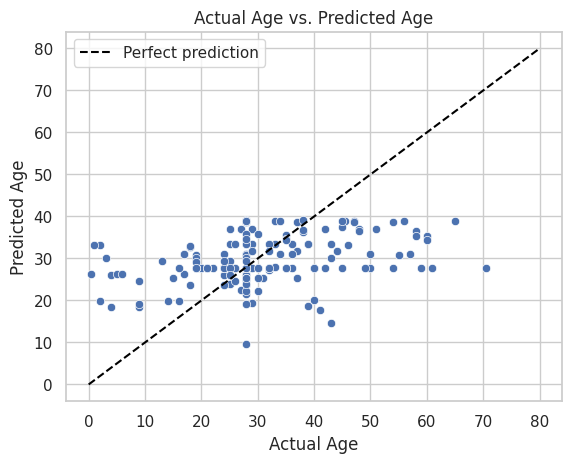

✓ One prediction per passenger
✓ Predictions are real numbers
✓ MAE is 11 years or less
✓ R² is at least 0.10

PROJECT COMPLETE!


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 14. PLOT AND CHECK THE MODEL
# ─────────────────────────────────────────────────────────────────────────────
sns.scatterplot(data=results, x="Actual Age", y="Predicted Age")
plt.plot([0, 80], [0, 80], "--", color="black", label="Perfect prediction")
plt.title("Actual Age vs. Predicted Age")
plt.legend()
plt.show()

def check_model(actual, predicted, mae_value, r2_value):
    checks = {
        "One prediction per passenger": len(actual) == len(predicted),
        "Predictions are real numbers": np.isfinite(predicted).all(),
        "MAE is 11 years or less": mae_value <= 11,
        "R² is at least 0.10": r2_value >= 0.10,
    }
    for name, passed in checks.items():
        print("✓" if passed else "✗", name)
    return all(checks.values())

project_complete = check_model(testing_ages, predictions, mae, r2)
print("\nPROJECT COMPLETE!" if project_complete else "\nReview the unchecked items above.")


FINAL REFLECTION — Answer briefly in comments:
1. Why is predicting Age regression rather than classification?
2. In ordinary language, what does your MAE mean?
3. Is this model perfect? What information might improve it?


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 15. FINALIZE AND GET YOUR SUBMISSION PHRASE
# ─────────────────────────────────────────────────────────────────────────────
# This phrase appears only after both parts of the project pass their checks.
# Copy the complete sentence exactly as it appears and submit it with your work.
if part_1_complete and project_complete:
    encoded_phrase = (
        "SmFjayBhbmQgUm9zZSBsb3ZlZCBlYWNoIG90aGVyLCBldmVuIGlmIGl0IHdhcyBzaG9ydCw"
        "gdGhhdCdzIHdoYXQgbWF0dGVyZWQu"
    )
    submission_phrase = base64.b64decode(encoded_phrase).decode("utf-8")

    print("\nSUBMISSION PHRASE:")
    print(submission_phrase)
else:
    print("\nFinish the unchecked project requirements to receive your submission phrase.")



SUBMISSION PHRASE:
Jack and Rose loved each other, even if it was short, that's what mattered.
